# ĐỒ ÁN PHÂN TÍCH DỮ LIỆU
## QUY TRÌNH 1.1: TỔNG QUAN DỮ LIỆU ĐẦU VÀO & PHÂN TÍCH ĐƠN BIẾN (EDA)
- **Thành viên thực hiện:** Trần Nhựt Hào
- **Nhiệm vụ theo phân công:**
  1. Tổng quan dữ liệu đầu vào: Metadata & Structure, Missing Values, Duplicate Values.
  2. Phân tích đơn biến: Inconsistent & Invalid Values, Giá trị ngoại lai, Phân tích phân phối dữ liệu.

In [ ]:
# Kết nối Google Drive nếu đang chạy trên Google Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # Chạy trên môi trường cục bộ (Jupyter Notebook / VS Code)

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
import re
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, spearmanr

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# Đường dẫn đến thư mục dữ liệu thô (tự động nhận diện local hoặc Google Colab)
RAW = Path("RAW_DATA/raw") if Path("RAW_DATA/raw").exists() else Path("/content/drive/MyDrive/[LTPTDL] Đồ án/raw")

FILES = [
    "Fact", "Calendar", "Business Line", "Group", "Subgroup",
    "Channel", "Region", "Headlines", "KPI", "Ratios"
]

# Đọc toàn bộ bảng dữ liệu dưới dạng chuỗi
tables = {
    f: pd.read_csv(RAW / f"{f}.csv", dtype=str, encoding="utf-8-sig")
    for f in FILES
}

fact = tables["Fact"]

# Kiểm tra kích thước các bảng
{name: df.shape for name, df in tables.items()}

{'Fact': (8726, 10),
 'Calendar': (360, 7),
 'Business Line': (3, 2),
 'Group': (4, 3),
 'Subgroup': (15, 3),
 'Channel': (3, 2),
 'Region': (3, 2),
 'Headlines': (7, 4),
 'KPI': (5, 3),
 'Ratios': (5, 2)}

# 1. EDA

## 1.1. Phân tích đơn biến

### 1.1.1. Metadata & Structure

Nhằm mục đích kiểm tra cấu trúc và quy mô của 10 bảng dữ liệu thông qua số dòng, số cột và số dòng trùng lặp, từ đó có cái nhìn tổng quan về bộ dữ liệu trước khi thực hiện EDA chi tiết.


In [ ]:
overview = pd.DataFrame({
    name: {
        "Rows": len(df),
        "Columns": df.shape[1],
        "Duplicates": df.duplicated().sum()
    }
    for name, df in tables.items()
}).T

overview

,Rows,Columns,Duplicates
Fact,8726,10,86
Calendar,360,7,0
Business Line,3,2,0
Group,4,3,0
Subgroup,15,3,0
Channel,3,2,0
Region,3,2,0
Headlines,7,4,0
KPI,5,3,0
Ratios,5,2,0


Nhận xét: Bảng Fact có 86 dòng trùng lặp, chiếm khoảng 0,99% tổng số dòng.Các bảng còn lại không xuất hiện dòng trùng lặp hoàn toàn.

### 1.1.2. Missing Values

In [ ]:
missing = pd.concat(
    {
        name: pd.DataFrame({
            "Missing_Count": df.isna().sum(),
            "Missing_Percent": (df.isna().mean() * 100).round(2)
        })
        for name, df in tables.items()
    },
    names=["Table", "Column"]
)

missing = missing[missing["Missing_Count"] > 0]
missing.sort_values("Missing_Percent", ascending=False)

Missing_Count  Missing_Percent
Table Column                                   
Fact  Channel              819             9.39
      Region               452             5.18
      Amount, $            253             2.90
      Date                 101             1.16

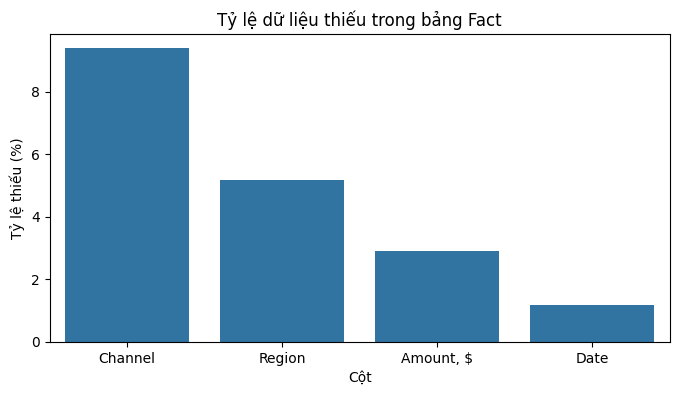

In [ ]:
plt.figure(figsize=(8, 4))
sns.barplot(
    data=missing.reset_index().sort_values("Missing_Percent", ascending=False),
    x="Column", y="Missing_Percent"
)
plt.title("Tỷ lệ dữ liệu thiếu trong bảng Fact")
plt.xlabel("Cột")
plt.ylabel("Tỷ lệ thiếu (%)")
plt.show()

Nhận xét: Chỉ bảng Fact có dữ liệu thiếu, tập trung ở Channel (9,39%), Region (5,18%), Amount (2,90%) và Date (1,16%). Điều này có thể ảnh hưởng đến phân tích tài chính, mùa vụ và hiệu quả theo kênh, khu vực.

### 1.1.3. Duplicate Values

Kết quả ở trên cho thấy chỉ bảng Fact có dòng trùng lặp. Vì vậy, phần này tập trung kiểm tra Fact theo hai tiêu chí: trùng toàn bộ dòng và trùng TransactionID (mã định danh duy nhất của mỗi giao dịch).

In [ ]:
duplicate_summary = pd.Series({
    "Duplicate Rows": fact.duplicated().sum(),
    "Duplicate TransactionID": fact["TransactionID"].duplicated().sum()
})

duplicate_summary

,0
Duplicate Rows,86
Duplicate TransactionID,86


Nhận xét: Bảng Fact ghi nhận 86 dòng trùng lặp hoàn toàn (0,99%) và 86 lượt trùng TransactionID. Điều này cho thấy các giao dịch có nguy cơ bị ghi nhận nhiều lần, làm sai lệch kết quả tổng hợp doanh thu, chi phí và lợi nhuận. Cần loại bỏ các bản ghi trùng sau khi xác minh trong bước tiền xử lý.

In [ ]:
#Xem chi tiết các dòng giao dịch bị trùng mã giao dịch
fact[fact["TransactionID"].duplicated(keep=False)].sort_values("TransactionID")

,TransactionID,Date,"Amount, $",Business Line ID,Business Line Name,Subgroup ID,Group ID,Revenue or expense,Channel,Region
70,T00071,NaN,"$1,747.68",1,Nutrition and Food Supplements,1,1,Revenue,Store,nam
8656,T00071,NaN,"$1,747.68",1,Nutrition and Food Supplements,1,1,Revenue,Store,nam
313,T00314,2023-01-14,1286.95 USD,1,Nutrition and Food Supplements,1,1,Revenue,NaN,Bắc
8660,T00314,2023-01-14,1286.95 USD,1,Nutrition and Food Supplements,1,1,Revenue,NaN,Bắc
8725,T00341,"Jan 15, 2023","$4,115.77",2,Sports equipment,1,1,Revenue,Distributor,Nam
...,...,...,...,...,...,...,...,...,...,...
8659,T08484,25/12/2023,"$2,312.35",1,Nutrition and Food Supplements,1,1,Revenue,Online,Trung
8641,T08533,2023-12-28,($3324.50),3,Sportswear,6,2,Expense,Store,Bắc
8532,T08533,2023-12-28,($3324.50),3,Sportswear,6,2,Expense,Store,Bắc
8669,T08587,30/12/2023,"-8.129,86",1,Nutrition and Food Supplements,14,3,Expense,Distributor,Nam


### 1.1.4. Inconsistent & Invalid Values

**a. Kiểm tra dữ liệu biến phân loại**

In [ ]:
cat_cols = ["Business Line Name", "Revenue or expense", "Channel", "Region"]

for col in cat_cols:
    print(f"\n{col}")
    display(fact[col].value_counts(dropna=False))


Business Line Name


,count
Business Line Name,
Sportswear,2919
Sports equipment,2904
Nutrition and Food Supplements,2903



Revenue or expense


,count
Revenue or expense,
Revenue,4227
Expense,4152
revenue,53
Rev,51
Revenue,49
REVENUE,46
Expenses,42
EXPENSE,40
expense,38



Channel


,count
Channel,
Online,3157
Store,2707
Distributor,1607
NaN,819
Online,68
online,66
Store,59
store,54
ONLINE,53



Region


,count
Region,
Nam,3486
Bắc,2703
Trung,1646
NaN,452
Nam,76
nam,65
bắc,63
Miền Nam,62
Miền Bắc,61


Nhận xét: Business Line Name không xuất hiện nhãn viết khác nhau. Revenue or expense, Channel và Region tồn tại nhiều cách ghi khác nhau dẫn đến có thể làm sai lệch kết quả phân nhóm. Các biến này cần được chuẩn hóa trong bước tiền xử lý.

**b. Kiểm tra tính hợp lệ của các khoá liên kết**

Mục đích: Kiểm tra tính hợp lệ của các mã định danh trong Fact, gồm Business Line ID (dòng sản phẩm), Group ID (nhóm doanh thu/chi phí) và Subgroup ID (khoản mục chi tiết), nhằm phát hiện các mã không tồn tại trong bảng danh mục, tránh sai lệch khi tích hợp và phân tích dữ liệu.

In [ ]:
keys = {
    "Business Line ID": "Business Line",
    "Group ID": "Group",
    "Subgroup ID": "Subgroup"
}

invalid_keys = pd.Series({
    col: (~fact[col].isin(tables[table][col]) & fact[col].notna()).sum()
    for col, table in keys.items()
}, name="Invalid_Count")

invalid_keys

,Invalid_Count
Business Line ID,18
Group ID,0
Subgroup ID,26


Nhận xét: Bảng Fact có 18 giá trị Business Line ID và 26 giá trị Subgroup ID không hợp lệ (không có trong bảng danh mục), còn Group ID đều nằm trong danh mục. Các mã sai có thể ảnh hưởng đến việc phân loại và tích hợp dữ liệu, cần được kiểm tra và xử lý ở bước tiền xử lý.

**c. Kiểm tra định dạng Amount**

In [ ]:
amount = fact["Amount, $"].dropna()

# Kiểm tra các giá trị không đúng định dạng số thông thường
invalid_amount = pd.to_numeric(amount, errors="coerce").isna()

pd.DataFrame({
    "Amount": amount[invalid_amount],
}).drop_duplicates().head(20)

,Amount
1,"$1,632.79"
3,($6978.85)
4,($1011.47)
5,-18503.05 USD
6,($3786.31)
7,"$9,812.00"
8,"($1,932.54)"
9,$2520.50
10,"($4,651.70)"
11,"($2,035.63)"


Nhận xét: Cột Amount có định dạng không nhất quán: ký hiệu $, USD, dấu phẩy phân cách hàng nghìn, dấu ngoặc biểu thị số âm và dấu phẩy thập phân. Những giá trị này cần được chuẩn hóa về kiểu số trước khi tính toán các chỉ tiêu tài chính.

**d. Kiểm tra định dạng Date**

In [ ]:
date = fact["Date"].dropna()

# Kiểm tra các giá trị không đúng định dạng YYYY-MM-DD
invalid_date = pd.to_datetime(
    date, format="%Y-%m-%d", errors="coerce"
).isna()

date[invalid_date].drop_duplicates().head(20)

,Date
2,"Jan 1, 2023"
20,01/01/2023
30,20230102
32,"Jan 2, 2023"
37,02/01/2023
55,03/01/2023
57,"Jan 3, 2023"
66,20230103
73,"Jan 4, 2023"
77,04/01/2023


Nhận xét: Cột Date tồn tại nhiều định dạng không nhất quán, gồm YYYY-MM-DD, DD/MM/YYYY, MMM D, YYYY và YYYYMMDD. Điều này có thể ảnh hưởng đến việc xác định tháng, quý và phân tích mùa vụ. Cần chuẩn hóa về một định dạng ngày thống nhất trong bước tiền xử lý.

### 1.1.5. Giá trị ngoại lai

Do các khoản mục tài chính có quy mô khác nhau, nhóm sử dụng phương pháp IQR trên thang log10|Amount| theo từng Subgroup, kết hợp Boxplot để phát hiện giá trị ngoại lai. Phương pháp này giúp hạn chế ảnh hưởng của sự chênh lệch quy mô giữa các khoản mục. Phân tích chỉ xét các giao dịch có Subgroup hợp lệ và Amount không thiếu, khác 0.

In [ ]:
eda = fact.copy()

def parse_amount(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    neg = s.startswith("(") or s.startswith("-")
    s = re.sub(r"USD|\$|[()\s-]", "", s, flags=re.I)
    if re.fullmatch(r"\d{1,3}(?:\.\d{3})+,\d{2}|\d+,\d{2}", s):   # kiểu VN: 6.720,07
        s = s.replace(".", "").replace(",", ".")
    else:                                                          # kiểu quốc tế: 1,632.79
        s = s.replace(",", "")
    return (-1 if neg else 1) * float(s)

eda["Amount_num"] = eda["Amount, $"].map(parse_amount)

In [ ]:
# Gắn tên khoản mục; Subgroup ID không có trong danh mục sẽ thành NaN và bị loại
sg_name = tables["Subgroup"].set_index("Subgroup ID")["Subgroup"]
eda["SG"] = eda["Subgroup ID"].map(sg_name)

d = eda.dropna(subset=["SG", "Amount_num"]).copy()
d = d[d["Amount_num"] != 0]
d["Log_Abs"] = np.log10(d["Amount_num"].abs())

# IQR tính riêng cho từng khoản mục
def iqr_flag(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

d["Outlier"] = d.groupby("SG")["Log_Abs"].transform(iqr_flag)

print(f"Số dòng bị gắn cờ: {d['Outlier'].sum()} / {len(d)} ({d['Outlier'].mean()*100:.1f}%)")
d.groupby("SG")["Outlier"].agg(["sum", "size"]).rename(columns={"sum": "Số outlier", "size": "Tổng dòng"})

Số dòng bị gắn cờ: 72 / 8449 (0.9%)


,Số outlier,Tổng dòng
SG,,
Consulting and professional services,4,472
Equipment,1,277
Interest and tax,3,106
Labor,1,348
Marketing,5,415
Materials,9,716
Other,4,433
Other income,1,278
Packaging,4,433


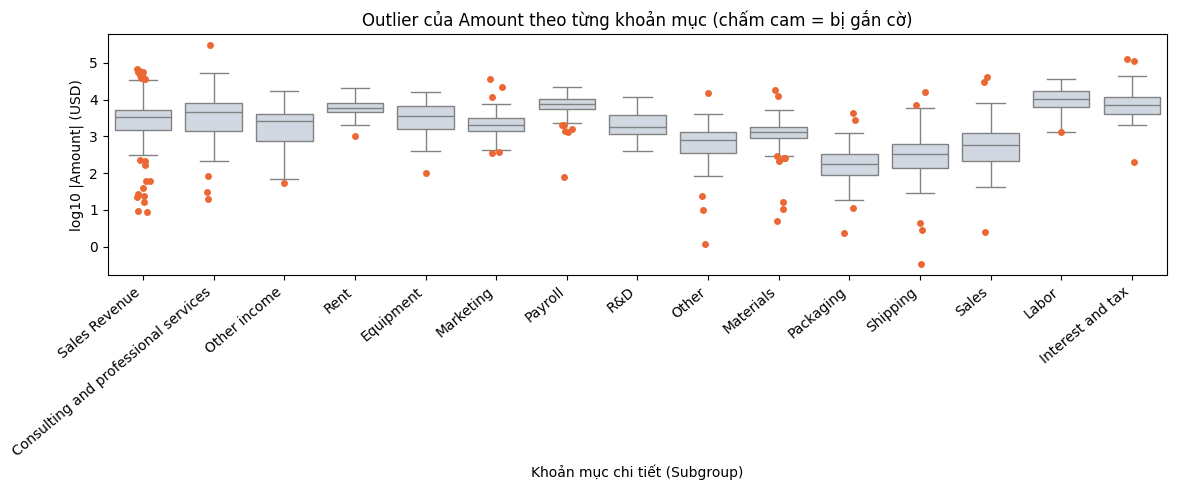

In [ ]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=d, x="SG", y="Log_Abs", order=sg_name.tolist(),
            showfliers=False, color="#cfd8e3")
sns.stripplot(data=d[d["Outlier"]], x="SG", y="Log_Abs", order=sg_name.tolist(),
              color="#eb6834", size=5)
plt.xticks(rotation=40, ha="right")
plt.xlabel("Khoản mục chi tiết (Subgroup)")
plt.ylabel("log10 |Amount| (USD)")
plt.title("Outlier của Amount theo từng khoản mục (chấm cam = bị gắn cờ)")
plt.tight_layout()
plt.show()

Nhận xét: Amount lệch phải mạnh và quy mô mỗi khoản mục khác nhau nên nhóm lấy log10 |Amount| rồi dùng IQR riêng cho từng khoản mục. Kết quả có 72/8.449 dòng (khoảng 0,9%) bị gắn cờ, trong đó Sales Revenue nhiều nhất (25 dòng), tiếp theo là Materials (9), Payroll (6), Marketing (5) và Shipping (5); R&D không có. Outlier xuất hiện ở cả phía cao lẫn phía thấp. Các dòng này cần được đối chiếu lại ở bước tiền xử lý vì không phải giá trị nào cũng là dữ liệu sai.

### 1.1.6. Phân tích phân phối dữ liệu

Vì Amount có cả doanh thu dương và chi phí âm nên phân tích phân phối riêng theo từng nhóm tài chính (Group ID).

In [ ]:
distribution = eda.groupby("Group ID")["Amount_num"].agg(
    Count="count",
    Mean="mean",
    Median="median",
    Std="std",
    Skewness="skew"
).round(2)

distribution

,Count,Mean,Median,Std,Skewness
Group ID,,,,,
1,4240,4049.70,3218.98,6283.76,26.83
2,1617,-3378.25,-2008.87,3866.48,-1.39
3,2469,-2467.29,-720.57,5147.04,-3.35
4,147,-6959.40,-4761.40,15896.80,-4.51


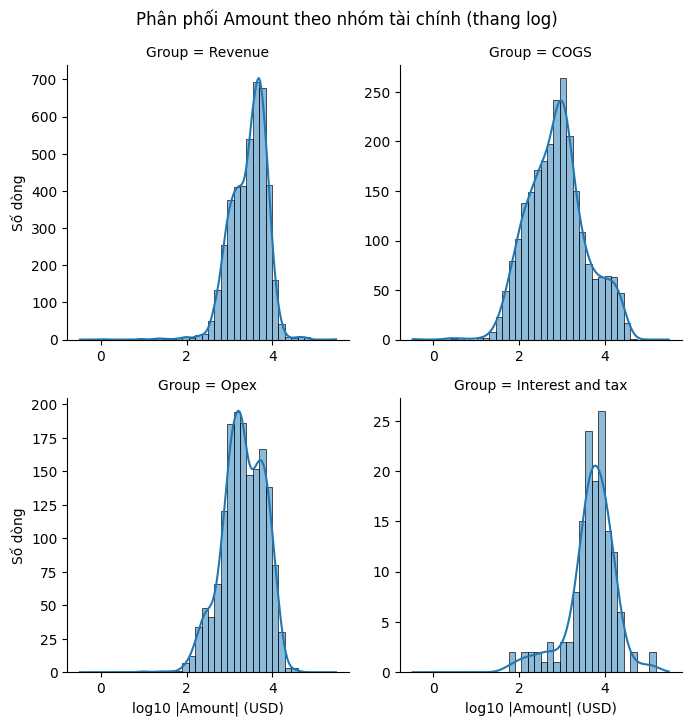

In [ ]:
# Gắn tên nhóm cho dễ đọc, rồi vẽ phân phối trên log10 |Amount|
group_name = tables["Group"].set_index("Group ID")["Group"]
eda["Group"] = eda["Group ID"].map(group_name)
eda["Log_Abs"] = np.log10(eda["Amount_num"].abs().replace(0, np.nan))

g = sns.displot(
    data=eda, x="Log_Abs", col="Group", col_order=group_name.tolist(),
    col_wrap=2, bins=40, kde=True, height=3.5,
    facet_kws={"sharex": False, "sharey": False}
)
g.set_axis_labels("log10 |Amount| (USD)", "Số dòng")
g.fig.suptitle("Phân phối Amount theo nhóm tài chính (thang log)", y=1.03)
plt.show()

Nhận xét: Revenue lệch phải rất mạnh (Skewness = 26,83), cho thấy một số giá trị rất lớn kéo Mean lên cao hơn Median. Các nhóm chi phí lệch trái do mang giá trị âm, trong đó COGS và Interest & Tax lệch rõ, còn Opex ở mức vừa (Skewness = -1,39). Mean và Median chênh lệch đáng kể ở hầu hết các nhóm, cho thấy ảnh hưởng của các giá trị cực đoan. Biểu đồ trên thang log giúp quan sát rõ hơn phân bố của các giao dịch có quy mô khác nhau. Các thống kê này tính trên dữ liệu chưa làm sạch ở mức giao dịch; việc chọn phương pháp kiểm định sẽ dựa trên phân phối của các biến tổng hợp dùng trong từng câu hỏi nghiên cứu.